# 03b — Clustering (tipología de condiciones)

Este cuaderno **mide, no decide**: reporta todos los k=2–12 y deja la elección al cuaderno siguiente (03e).
Regla de este bloque: `clc_class` (nominal) queda fuera de las distancias y vive en perfiles; `franja_horaria` entra codificada ordinalmente (`encode_franja_horaria`).

Recordatorio de las features:
- `features_a.csv` (7: PCs del clima)
- `features_b.csv` (12: + estacionalidad y hora)
- `features_c.csv` (25: + suelo)
- `perfilado.csv` (31: satélite, presupuestos, índices)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, fcluster
from sklearn.metrics import normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler
from wildfire.data.io import load_csv, save_csv
from wildfire.processing.unsupervised import (
    ENTRADA_A, ENTRADA_B, ENTRADA_C_FIXED, ID_COL, PERFILADO,
    assert_feature_sets_clean, check_ids, distance_columns, encode_franja_horaria,
    fit_gmm_range, fit_kmeans_range, gmm_bic_table, load_min_cliff_delta,
    max_pairwise_cliffs_delta, negative_control_partitions,
    resolve_set, sample_frame, ward_linkage,
)

*`full` bajo `diag` en todo k y conjunto; mínimo `full` en k=12 salvo C (k=11) — borde del rango, 03e valora si ampliar.*

## 03b.1 — Carga y escalado descriptivo

Se cargan `features_a/b/c.csv` y el perfilado, se codifica `franja_horaria` a ordinal en B y C, y se recorta cada conjunto a columnas numéricas —`clc_class` sale de las distancias y vive en los perfiles—. Se verifica `detection_id` entre los cuatro ficheros y la clave queda fuera de las distancias. Después se estandariza cada conjunto por separado: es un escalado descriptivo (plan §4 regla 3) que no se reutiliza para modelar.

Cómo leer la salida `a: crudo (filas, columnas) (todas numéricas: True)`: forma sin escalar y comprobación de que KMeans/GMM reciben solo números (con texto fallarían en silencio o a lo bruto).

In [2]:
sets_raw = {
    name: load_csv(f"data/processed/unsupervised/features_{name}.csv")
    for name in ("a", "b", "c")
}
perfilado = load_csv("data/processed/unsupervised/perfilado.csv")
# Clave primero: a partir de aquí todo join es por detection_id (verificado),
# lo posicional dentro de la celda queda guardado por este assert.
ids = check_ids(sets_raw["a"], sets_raw["b"], sets_raw["c"], perfilado)
frp = perfilado["frp"].to_numpy()
sets_raw["b"] = encode_franja_horaria(sets_raw["b"])
sets_raw["c"] = encode_franja_horaria(sets_raw["c"])
inputs = {
    "a": sets_raw["a"].drop(columns=[ID_COL]),
    "b": sets_raw["b"].drop(columns=[ID_COL]),
    "c": resolve_set(sets_raw["c"], distance_columns([c for c in sets_raw["c"].columns]), "C"),
}
X = {name: pd.DataFrame(StandardScaler().fit_transform(frame), columns=frame.columns, index=frame.index)
     for name, frame in inputs.items()}
for _name, _frame in inputs.items():
    print(f"{_name}: crudo {_frame.shape} (todas numéricas: {all(pd.api.types.is_numeric_dtype(t) for t in _frame.dtypes)})")


a: crudo (23142, 7) (todas numéricas: True)
b: crudo (23142, 12) (todas numéricas: True)
c: crudo (23142, 24) (todas numéricas: True)


## 03b.2 — KMeans k=2–12 (línea base)

Se ajusta KMeans para cada k y se guardan las etiquetas en ancho (columnas `k_2`…`k_12`, índice común) en `clustering_kmeans_{a,b,c}.csv`.

Cómo leer cada tabla (una por conjunto a/b/c):
- `inertia`: suma de distancias al centroide; siempre baja al subir k. Se busca el *codo* (donde deja de compensar añadir grupos), no el mínimo.
- `silhouette` (−1…1): cohesión dentro del grupo frente a separación. ~0,2 es bajo pero esperado: condiciones continuas sin fronteras nítidas (plan §6.1).
- `calinski_harabasz`: más alto = grupos más densos y separados (dispersión entre/dentro).
- `davies_bouldin`: más bajo = mejor (similitud media entre cada grupo y su vecino más parecido).
Ninguna decide k por sí sola: 03e cruza las cuatro + estabilidad + severidad.

In [3]:
kmeans_labels, kmeans_metrics = {}, {}
for _name, _X in X.items():
    _lab, _met = fit_kmeans_range(_X)
    kmeans_labels[_name], kmeans_metrics[_name] = _lab, _met
    display(_met.round(3))
    save_csv(pd.DataFrame({"detection_id": ids, **{f"k_{k}": v for k, v in _lab.items()}}, index=_X.index),
             f"data/processed/unsupervised/clustering_kmeans_{_name}.csv")
print("Etiquetas KMeans guardadas.")

,inertia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,142618.469,0.147,3143.751,2.439
3,128071.829,0.164,3064.442,2.105
4,109678.277,0.170,3678.892,1.610
5,99570.865,0.175,3626.282,1.558
6,89116.406,0.203,3784.077,1.405
7,81273.653,0.205,3829.592,1.344
8,74142.577,0.216,3915.934,1.258
9,68391.018,0.227,3957.619,1.231
10,64483.620,0.225,3886.621,1.244


,inertia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,217993.455,0.227,6338.276,1.788
3,191095.047,0.212,5243.581,1.746
4,174723.738,0.213,4545.778,1.698
5,161679.203,0.212,4150.915,1.653
6,144447.725,0.217,4268.697,1.434
7,132386.205,0.222,4232.477,1.463
8,125938.334,0.220,3982.621,1.501
9,120730.576,0.210,3759.692,1.576
10,115199.087,0.199,3625.681,1.535


,inertia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,486116.314,0.144,3298.408,2.431
3,458809.712,0.107,2435.863,2.514
4,433991.150,0.126,2157.758,2.350
5,412942.013,0.152,1995.582,2.159
6,391195.262,0.158,1942.369,2.114
7,369290.853,0.178,1943.284,2.027
8,346630.987,0.189,1990.527,1.735
9,330296.374,0.208,1970.781,1.784
10,309403.227,0.207,2043.570,1.531


Etiquetas KMeans guardadas.


*En este run: sin codo nítido — A sube hasta k=12 (0,243), B pica en k=2 (0,227), C en k=9 (0,208); 03e cruza las cuatro métricas.*

## 03b.3 — GMM full/diag por BIC (pertenencia suave)

Se ajustan mezclas gaussianas para cada (k, covarianza) y se guardan las etiquetas; las probabilidades de pertenencia, más honestas que la etiqueta dura cuando los regímenes se solapan, se guardan además en `cluster_labels.csv` para que las use 03e: etiquetas duras KMeans/GMM y columnas `gmm_{conjunto}_k5_{cov}_p{j}` (suman 1 por fila) al k=5 ilustrativo de todo el bloque, con ambas covarianzas — si 03e elige otro k, re-ajusta allí.

Cómo leer cada tabla BIC (una por conjunto): filas = k, columnas = tipo de covarianza. Menor BIC = mejor equilibrio entre ajuste y complejidad (penaliza parámetros de más).
- `full`: elipses orientadas (captura correlaciones, p. ej. calor–sequedad de PC1).
- `diag`: ejes alineados (menos parámetros, supone variables independientes).
Con las 14 crudas `full` ganaba de largo porque las meteorológicas están correlacionadas; con los PCs —decorrelacionados *globalmente* por construcción— `full` sigue ganando en los tres conjuntos y a todo k: dentro de cada régimen las nubes siguen siendo elipses orientadas, que es justo lo que captura la covarianza completa.


In [4]:
gmm_results, gmm_bics = {}, {}
for _name, _X in X.items():
    _res = fit_gmm_range(_X)
    gmm_results[_name] = _res
    _bic = gmm_bic_table(_res)
    gmm_bics[_name] = _bic
    display(_bic.round(0))
    save_csv(pd.DataFrame({"detection_id": ids, **{f"k_{k}_{cov}": r["labels"] for (k, cov), r in _res.items()}}, index=_X.index),
             f"data/processed/unsupervised/clustering_gmm_{_name}.csv")
print("Etiquetas GMM guardadas.")

_k_ilus = 5  # k ilustrativo del bloque (sonda ARI de 03a, mapas de 03b.7); el definitivo lo decide 03e
cluster_labels = pd.DataFrame({"detection_id": ids}, index=X["a"].index)
for _sname in ("a", "b", "c"):
    cluster_labels[f"kmeans_{_sname}_k{_k_ilus}"] = kmeans_labels[_sname][_k_ilus]
    for _cov in ("full", "diag"):
        _res = gmm_results[_sname][(_k_ilus, _cov)]
        cluster_labels[f"gmm_{_sname}_k{_k_ilus}_{_cov}"] = _res["labels"]
        cluster_labels[[f"gmm_{_sname}_k{_k_ilus}_{_cov}_p{_j}" for _j in range(_k_ilus)]] = _res["proba"]
save_csv(cluster_labels, "data/processed/unsupervised/cluster_labels.csv")
print(f"cluster_labels.csv: {cluster_labels.shape} (etiquetas duras + probabilidades GMM, k={_k_ilus})")


covariance,diag,full
k,,
2,437926.0,349119.0
3,427664.0,330650.0
4,414939.0,313573.0
5,407913.0,294861.0
6,393886.0,284135.0
7,390679.0,280369.0
8,388020.0,271935.0
9,386779.0,260521.0
10,380589.0,254284.0


covariance,diag,full
k,,
2,696503.0,436811.0
3,646635.0,399402.0
4,524223.0,65000.0
5,457251.0,103988.0
6,382690.0,8525.0
7,321633.0,133010.0
8,266777.0,24668.0
9,173053.0,-32672.0
10,175206.0,-68629.0


covariance,diag,full
k,,
2,708515.0,117106.0
3,137837.0,-468713.0
4,-295062.0,-851827.0
5,-326728.0,-927327.0
6,-568850.0,-1013484.0
7,-781675.0,-1249207.0
8,-1051075.0,-1347680.0
9,-1237197.0,-1493226.0
10,-1259574.0,-1421318.0


Etiquetas GMM guardadas.


cluster_labels.csv: (23142, 40) (etiquetas duras + probabilidades GMM, k=5)


## 03b.4 — Ward sobre muestra de 5.000 (estimación independiente de k)

Un jerárquico aglomerativo, que no pide k por adelantado, sobre una muestra determinista; la matriz de linkage se guarda en `ward_linkage_a.csv`.

Cómo leer la salida:
- `Últimas 5 fusiones (dist, tamaño)`: a qué distancia se unen dos ramas y cuántos puntos suma la rama resultante. Un salto grande entre fusiones marca un corte natural candidato: lo que se une a una distancia muy superior a las fusiones previas estaba muy separado. En esta corrida las últimas fusiones escalan suave (~67→78), sin salto dramático: Ward no ve un corte evidente, y eso también es información para 03e.
- Dendrograma truncado a 20 ramas: la altura de cada unión = disimilitud de fusión; ramas que se unen abajo son parecidas, las que suben hasta arriba son regímenes distintos. Si el corte natural discrepa de BIC/codo, 03e lo recoge.

Últimas 5 fusiones (dist, tamaño):
[[  67.49668285  621.        ]
 [  68.13879158 2351.        ]
 [  72.62396917 1456.        ]
 [  75.97449828 3807.        ]
 [  78.32111113 5000.        ]]


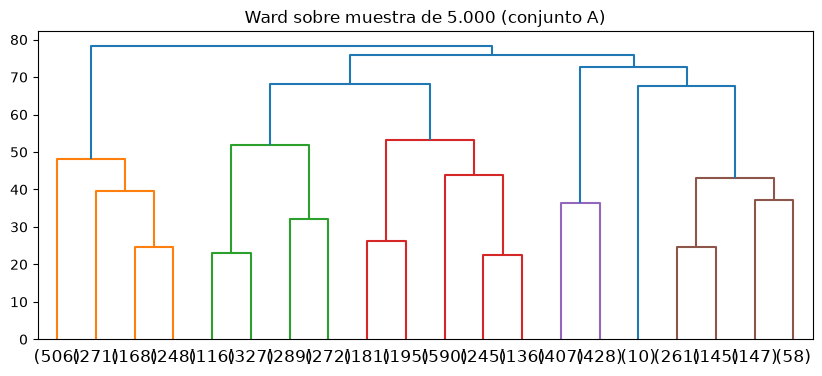

In [5]:
_sample = sample_frame(X["a"], 5_000)
_Z = ward_linkage(_sample)
save_csv(pd.DataFrame(_Z, columns=["a", "b", "dist", "n"]),
         "data/processed/unsupervised/ward_linkage_a.csv")
print("Últimas 5 fusiones (dist, tamaño):")
print(_Z[-5:, 2:])
fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(_Z, truncate_mode="lastp", p=20, ax=ax)
ax.set_title("Ward sobre muestra de 5.000 (conjunto A)")
plt.show()

## 03b.5 — Controles negativos + separación de severidad (medición §7B)

Primero las particiones tontas —mes (12 grupos) y CCAA (17)— como listón a batir; después, para cada (conjunto, k), la mayor |δ de Cliff| entre pares de grupos sobre `frp`. Todo queda en `severidad_kmeans.csv`.

Cómo leer la tabla:
- `max_abs_delta` (0…1): 0 = los dos grupos arden igual; 1 = uno siempre más virulento. Regla intuitiva: (1+δ)/2 = probabilidad de que una detección al azar del grupo fiero supere a una del manso.
- `par`: qué dos grupos marcan el máximo (etiquetas internas, sin significado físico).
- Filas `control_ccaa` (0,699) y `control_month` (0,401): el listón. La candidata tiene que superarlas *sin ser ellas* (eso lo comprueba la NMI de 03b.6).
- El umbral `unsupervised.min_cliff_delta` se imprime como referencia; lo aplica 03e, aquí solo se mide.

In [6]:
_controls = negative_control_partitions(perfilado)
_rows = []
for _cname, _clab in _controls.items():
    _d, _pair = max_pairwise_cliffs_delta(frp, _clab)
    _rows.append({"conjunto": f"control_{_cname}", "k": len(set(_clab.tolist())),
                  "max_abs_delta": abs(_d), "par": str(_pair)})
for _sname, _lab in kmeans_labels.items():
    for _k, _v in _lab.items():
        _d, _pair = max_pairwise_cliffs_delta(frp, _v)
        _rows.append({"conjunto": f"kmeans_{_sname}", "k": _k,
                      "max_abs_delta": abs(_d), "par": str(_pair)})
severity = pd.DataFrame(_rows).sort_values(["conjunto", "k"]).reset_index(drop=True)
display(severity.round(3))
print(f"Umbral §7B (solo referencia, decide 03e): {load_min_cliff_delta()}")
save_csv(severity, "data/processed/unsupervised/severidad_kmeans.csv")

,conjunto,k,max_abs_delta,par
0,control_ccaa,17,0.699,"(12, 13)"
1,control_month,12,0.401,"(4, 5)"
2,kmeans_a,2,0.096,"(0, 1)"
3,kmeans_a,3,0.237,"(0, 2)"
4,kmeans_a,4,0.674,"(1, 3)"
5,kmeans_a,5,0.714,"(2, 3)"
6,kmeans_a,6,0.704,"(3, 4)"
7,kmeans_a,7,0.847,"(1, 6)"
8,kmeans_a,8,0.794,"(1, 5)"
9,kmeans_a,9,0.838,"(4, 6)"


Umbral §7B (solo referencia, decide 03e): 0.7


WindowsPath('C:/Projects/wildfires-project/data/processed/unsupervised/severidad_kmeans.csv')

*Mejor KMeans: A/k=12 (0,863) sobre CCAA (0,699) y mes (0,401) — 03e lo aceptó como tipología tras comprobar estabilidad y tamaño.*

## 03b.6 — Perfiles e información mutua (medición, sin interpretar)

Medias por grupo en unidades originales (ºC, m/s, …) en `perfiles_kmeans_{a,b,c}.csv`, para describir 'cómo es' cada grupo sin hablar en z-scores; y NMI de cada partición contra `ccaa` y `month` en `nmi_kmeans.csv`.

Cómo leer las salidas:
- Tabla NMI: 0 = la partición no sabe nada de esa variable; > 0,5 = el grupo *es* esa variable (p. ej. redescubrió el calendario) y la candidata queda descalificada en 03e.
- `n_grupos`: comprobación de cordura — debe haber exactamente k grupos no vacíos por k (si KMeans devolviera grupos vacíos, algo iría mal).

In [7]:
profiles = {}
nmi_rows = []
for _sname, _lab in kmeans_labels.items():
    _raw = inputs[_sname]
    _frames = []
    for _k, _v in _lab.items():
        _m = _raw.groupby(_v).mean()
        _m["k"] = _k
        _m["grupo"] = _m.index
        _frames.append(_m.reset_index(drop=True))
        for _col in ("ccaa", "month"):
            nmi_rows.append({"conjunto": f"kmeans_{_sname}", "k": _k, "variable": _col,
                            "nmi": normalized_mutual_info_score(_v, perfilado[_col].astype(str))})
    profiles[_sname] = pd.concat(_frames, ignore_index=True)
    save_csv(profiles[_sname], f"data/processed/unsupervised/perfiles_kmeans_{_sname}.csv")
nmi = pd.DataFrame(nmi_rows)
display(nmi.round(3))
save_csv(nmi, "data/processed/unsupervised/nmi_kmeans.csv")
display(profiles["a"].groupby("k").size().rename("n_grupos"))

,conjunto,k,variable,nmi
0,kmeans_a,2,ccaa,0.049
1,kmeans_a,2,month,0.056
2,kmeans_a,3,ccaa,0.186
3,kmeans_a,3,month,0.176
4,kmeans_a,4,ccaa,0.180
...,...,...,...,...
61,kmeans_c,10,month,0.151
62,kmeans_c,11,ccaa,0.198
63,kmeans_c,11,month,0.259
64,kmeans_c,12,ccaa,0.167


k
2      2
3      3
4      4
5      5
6      6
7      7
8      8
9      9
10    10
11    11
12    12
Name: n_grupos, dtype: int64

*Máximo 0,536 (B vs mes, por encima del 0,5: B redescubre el calendario; A queda en 0,257 con CCAA).*

## 03b.7 — Mapas y mezcla por CCAA con k=5 (ilustrativo)

Para cerrar, dónde cae cada grupo con k=5 (el mismo k de la sonda ARI de 03a) y el cruce grupos × CCAA. Es ilustrativo —el k final lo decide 03e—, pero ya permite olfatear artefactos.

Cómo leer las salidas:
- Mapas: cada punto es una detección coloreada por grupo. Si un color ocupa una sola zona (p. ej. todo el noroeste), ese 'régimen meteorológico' es geografía disfrazada.
- Tabla de mezcla (filas = grupos, columnas = CCAA, filas suman 1): proporción de cada grupo en cada comunidad. Ejemplo de lectura: un grupo con 0,62 en Asturias + 0,14 en Cantabria es mayoritariamente quema norteña de invierno, no un régimen estatal; otro con 0,82 en Canarias huele a geografía disfrazada.

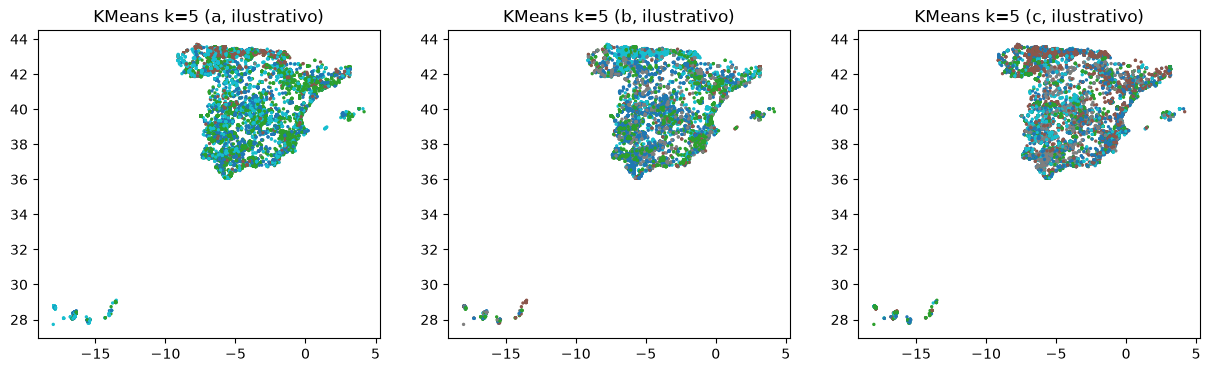

ccaa,Andalucía,Aragón,Asturias,Canarias,Cantabria,Castilla y León,Castilla-La Mancha,Cataluña,Comunidad Valenciana,Extremadura,Galicia,Islas Baleares,La Rioja,Madrid,Navarra,País Vasco,Región de Murcia
row_0,,,,,,,,,,,,,,,,,
0,0.23,0.03,0.01,0.30,0.01,0.05,0.12,0.04,0.06,0.08,0.01,0.00,0.00,0.02,0.01,0.00,0.02
1,0.18,0.06,0.10,0.05,0.02,0.07,0.08,0.06,0.15,0.13,0.02,0.01,0.01,0.00,0.01,0.00,0.04
2,0.02,0.01,0.62,0.00,0.14,0.08,0.01,0.01,0.01,0.01,0.05,0.00,0.00,0.00,0.03,0.01,0.00
3,0.04,0.00,0.00,0.82,0.01,0.06,0.00,0.00,0.06,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.00
4,0.12,0.03,0.06,0.13,0.02,0.10,0.06,0.02,0.04,0.28,0.09,0.01,0.00,0.01,0.01,0.00,0.02


03b medición completa: 03e decide.


In [8]:
_k = 5
_coords = load_csv("data/processed/expanded/firms_spain_final_lags_index.csv")[["detection_id", "longitude", "latitude"]]
check_ids(_coords, sets_raw["a"])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for _ax, _sname in zip(axes, ("a", "b", "c")):
    _lab = kmeans_labels[_sname][_k]
    _sc = _ax.scatter(_coords["longitude"], _coords["latitude"], c=_lab, s=2, cmap="tab10")
    _ax.set_title(f"KMeans k={_k} ({_sname}, ilustrativo)")
plt.show()
_mix = pd.crosstab(kmeans_labels["a"][_k], perfilado["ccaa"], normalize="index").round(2)
display(_mix)
print("03b medición completa: 03e decide.")

*Etiquetas no comparables entre paneles: el 'grupo 0' de A no es el de B. Solo se compara el patrón.*